<a href="https://colab.research.google.com/github/alameenShameer/Churn_Prediction_Classification/blob/main/Churn_Prediction_Classification_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [365]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree


from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,precision_score,f1_score,recall_score

pd.set_option('display.max_columns',None)

In [366]:
data_path='/content/drive/MyDrive/ICT AI ML Files/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(data_path)

In [367]:
df.shape

(7043, 21)

In [368]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [369]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [370]:
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [371]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [372]:
df.duplicated().sum()

np.int64(0)

In [373]:
df['SeniorCitizen'].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


In [374]:
cat_cols=df.select_dtypes(include='object').columns
for col in df.columns:
  print(f'{col} --> {df[col].unique()}')

customerID --> ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender --> ['Female' 'Male']
SeniorCitizen --> [0 1]
Partner --> ['Yes' 'No']
Dependents --> ['No' 'Yes']
tenure --> [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService --> ['No' 'Yes']
MultipleLines --> ['No phone service' 'No' 'Yes']
InternetService --> ['DSL' 'Fiber optic' 'No']
OnlineSecurity --> ['No' 'Yes' 'No internet service']
OnlineBackup --> ['Yes' 'No' 'No internet service']
DeviceProtection --> ['No' 'Yes' 'No internet service']
TechSupport --> ['No' 'Yes' 'No internet service']
StreamingTV --> ['No' 'Yes' 'No internet service']
StreamingMovies --> ['No' 'Yes' 'No internet service']
Contract --> ['Month-to-month' 'One year' 'Two year']
PaperlessBilling --> ['Yes' 'No']
PaymentMethod --> ['Elect

In [375]:
# df['TotalCharges']=df['TotalCharges'].astype(float)
print((df['TotalCharges']==' ').sum())

11


In [376]:
df['TotalCharges']=df['TotalCharges'].replace(' ',np.nan)

In [377]:
df['TotalCharges']=df['TotalCharges'].astype(float)


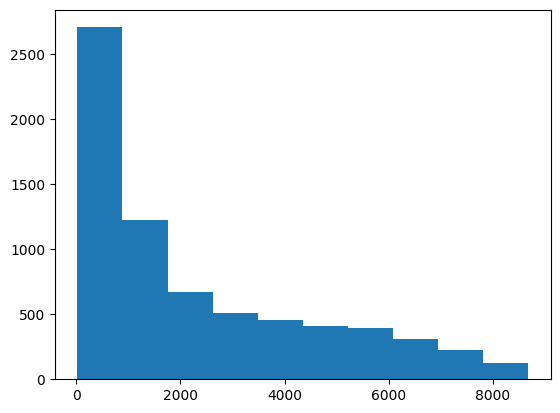

In [378]:
plt.hist(df['TotalCharges'])
plt.show()

In [379]:
(df.isna().sum()/len(df)*100)

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


In [380]:
df.dropna(inplace=True)

In [381]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

#Train test split

In [382]:
df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


In [383]:
X,y = df.drop(['customerID','Churn'],axis=1),df['Churn']
# print(X.columns)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [384]:
# median_value = X_train['TotalCharges'].median()

# X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median_value)
# X_test['TotalCharges'] = X_test['TotalCharges'].fillna(median_value)

In [385]:
scale_cols=['MonthlyCharges','TotalCharges','tenure']

In [386]:
scaler = StandardScaler()

X_train_scale=pd.DataFrame(
  scaler.fit_transform(X_train[scale_cols]),
  columns=scale_cols,
  index=X_train.index
)
X_test_scale=pd.DataFrame(
  scaler.transform(X_test[scale_cols]),
  columns=scale_cols,
  index=X_test.index
)
# type(X_test_scale)

In [387]:
cat_cols=X_train.select_dtypes(include='object').columns
one_hot_encoder=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X_train_encode=one_hot_encoder.fit_transform(X_train[cat_cols])
X_test_encode=one_hot_encoder.transform(X_test[cat_cols])

column_names=one_hot_encoder.get_feature_names_out(cat_cols)

X_train_encode=pd.DataFrame(
    X_train_encode,
    columns=column_names,
    index=X_train.index
)

X_test_encode=pd.DataFrame(
    X_test_encode,
    columns=column_names,
    index=X_test.index
)

In [388]:
X_train_final=pd.concat([X_train_scale,X_train_encode,X_train['SeniorCitizen']],axis=1)
X_test_final=pd.concat([X_test_scale,X_test_encode,X_test['SeniorCitizen']],axis=1)


In [389]:
label_encoder=LabelEncoder()
y_train_final=pd.Series(label_encoder.fit_transform(y_train),index=y_train.index)
y_test_final=pd.Series(label_encoder.transform(y_test),index=y_test.index)

In [390]:
smote = SMOTE(random_state=42)
X_train_balanced,y_train_balanced = smote.fit_resample(X_train_final,y_train_final)

In [391]:
y_train_balanced.value_counts()

,count
0,4130
1,4130


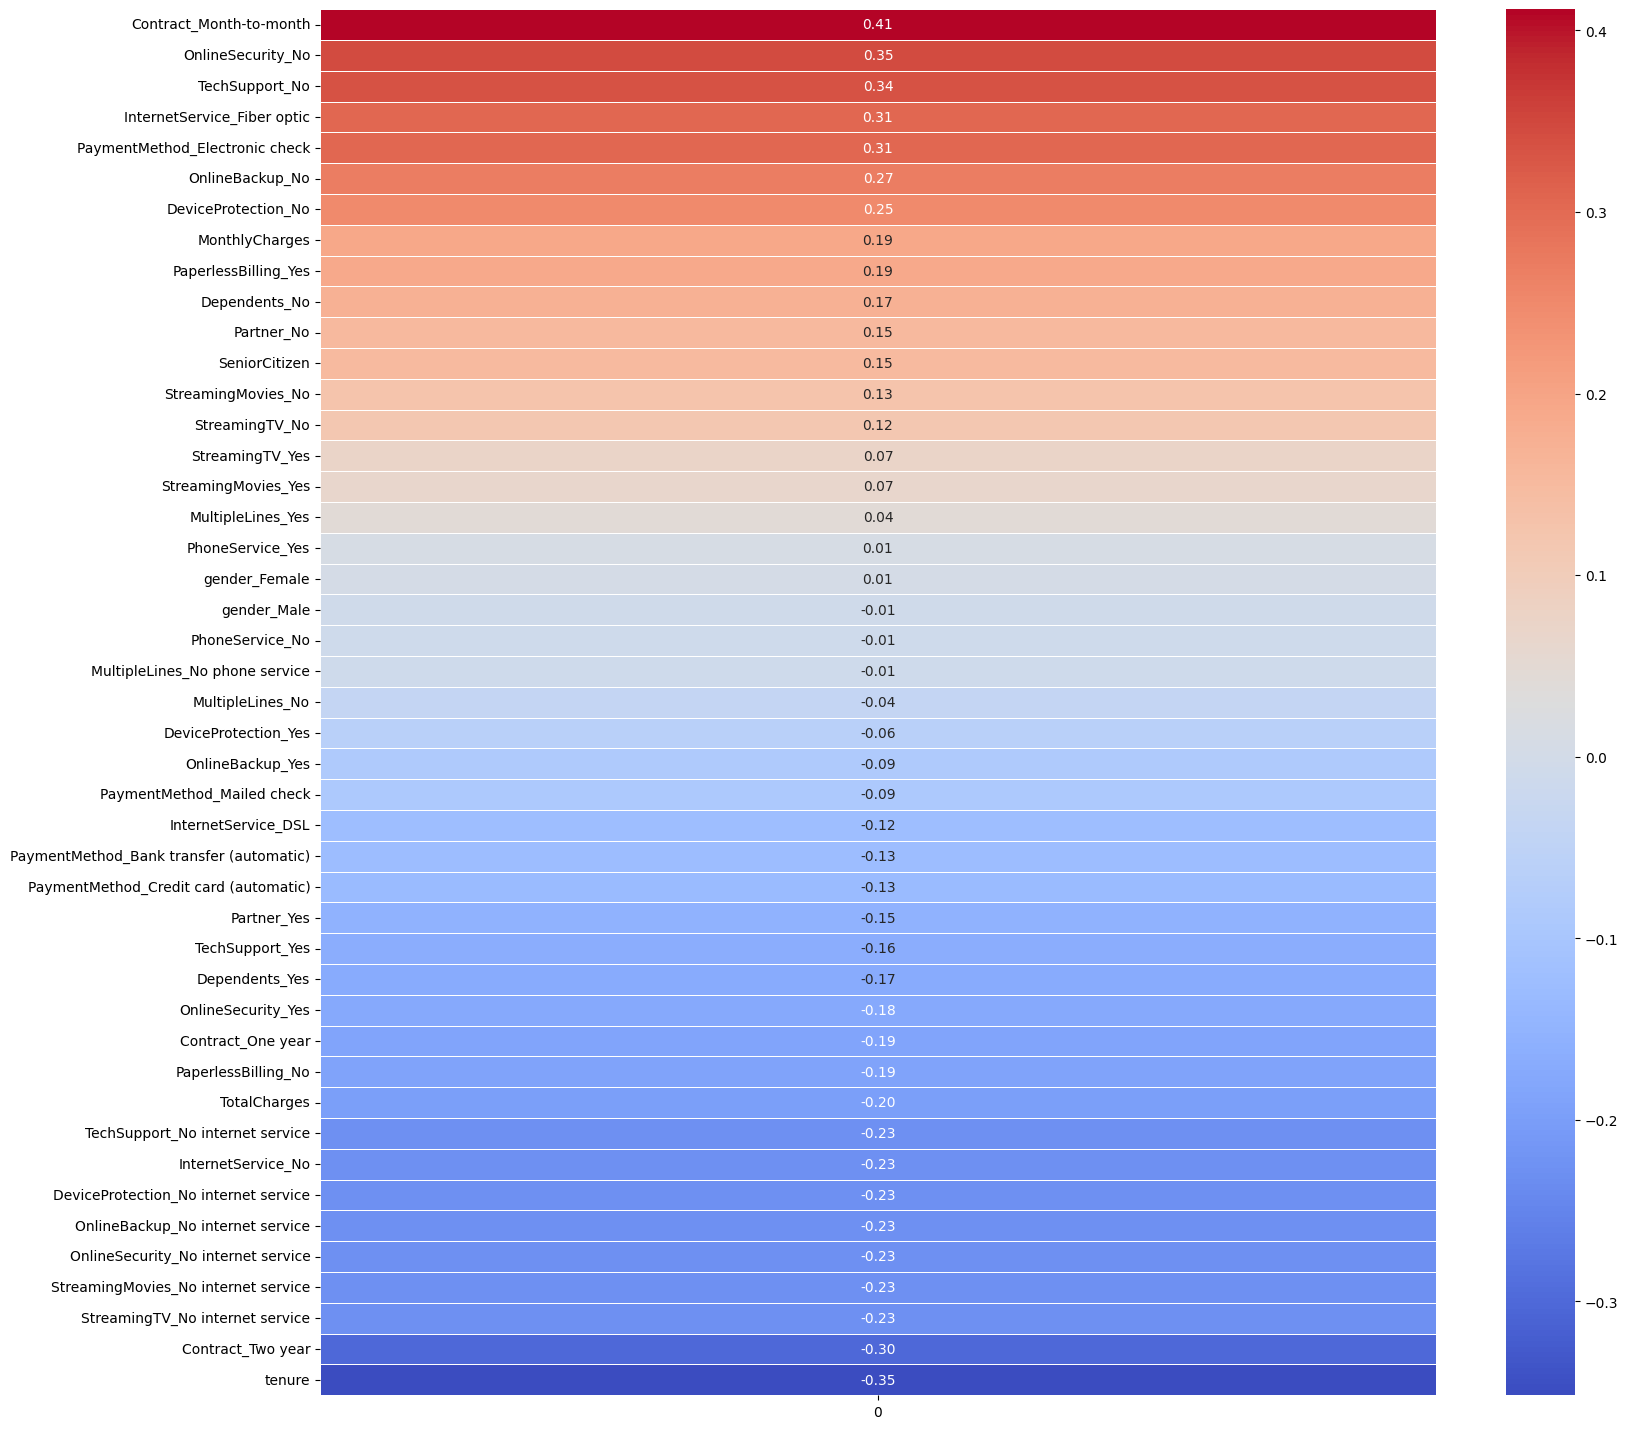

In [392]:
corr=X_train_final.corrwith(y_train_final).sort_values(ascending=False).to_frame()

plt.figure(figsize=(18,18))
sns.heatmap(corr,annot=True,linewidth=0.5,fmt='.2f',cmap='coolwarm')
plt.show()

# print(corr)

In [393]:
X_train.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

In [394]:
selected_cols=['OnlineBackup_No','tenure', 'Contract_Month-to-month']

In [395]:
X_train_selected=X_train_balanced[selected_cols]
X_test_selected=X_test_final[selected_cols]


Accuracy Score: 0.6687988628287136
Confusion Matrix
[[628 405]
 [ 61 313]]
Classification Report
              precision    recall  f1-score   support

           0       0.91      0.61      0.73      1033
           1       0.44      0.84      0.57       374

    accuracy                           0.67      1407
   macro avg       0.67      0.72      0.65      1407
weighted avg       0.79      0.67      0.69      1407



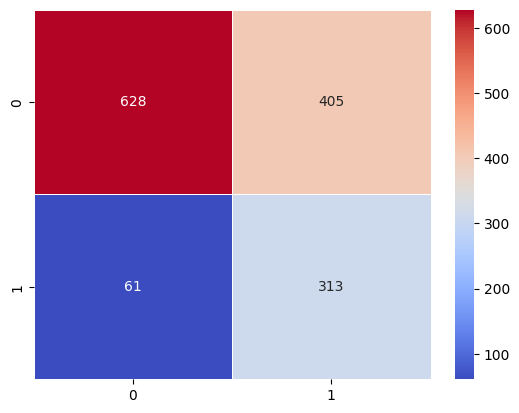

In [396]:
log_reg=LogisticRegression()
log_reg.fit(X_train_selected,y_train_balanced)
log_reg_pred=log_reg.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, log_reg_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, log_reg_pred))

print('Classification Report')
print(classification_report(y_test_final, log_reg_pred))

sns.heatmap(
    confusion_matrix(y_test_final, log_reg_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

Accuracy Score: 0.7313432835820896
Confusion Matrix
[[860 173]
 [205 169]]
Classification Report
              precision    recall  f1-score   support

           0       0.81      0.83      0.82      1033
           1       0.49      0.45      0.47       374

    accuracy                           0.73      1407
   macro avg       0.65      0.64      0.65      1407
weighted avg       0.72      0.73      0.73      1407



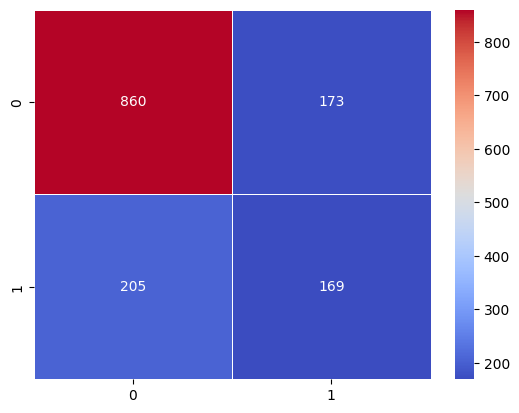

In [397]:
knn = KNeighborsClassifier(n_neighbors=17)
knn.fit(X_train_selected,y_train_balanced)
knn_pred=knn.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, knn_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, knn_pred))

print('Classification Report')
print(classification_report(y_test_final, knn_pred))

sns.heatmap(
    confusion_matrix(y_test_final, knn_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

In [398]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(knn_pred).value_counts())

Actual values:
0    1033
1     374
Name: count, dtype: int64
Predicted values:
0    1065
1     342
Name: count, dtype: int64


In [399]:
print(label_encoder.classes_)

['No' 'Yes']


In [400]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(log_reg_pred).value_counts())

Actual values:
0    1033
1     374
Name: count, dtype: int64
Predicted values:
1    718
0    689
Name: count, dtype: int64


In [401]:
# Get probability of Churn (class 1)
y_prob = log_reg.predict_proba(X_test_selected)[:, 1]

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print("Accuracy:", accuracy_score(y_test_final, y_pred_threshold))
    print("Precision:", precision_score(y_test_final, y_pred_threshold))
    print("Recall:", recall_score(y_test_final, y_pred_threshold))
    print("F1 Score:", f1_score(y_test_final, y_pred_threshold))


Threshold: 0.3
Accuracy: 0.6318407960199005
Precision: 0.40977443609022557
Recall: 0.8743315508021391
F1 Score: 0.5580204778156996

Threshold: 0.5
Accuracy: 0.6687988628287136
Precision: 0.435933147632312
Recall: 0.8368983957219251
F1 Score: 0.5732600732600732

Threshold: 0.7
Accuracy: 0.7448471926083866
Precision: 0.5184275184275184
Recall: 0.5641711229946524
F1 Score: 0.5403329065300896


Lowering the classification threshold increases recall because more customers are classified as potential churners. At a threshold of 0.3, the model achieves the highest recall of 88.50%. At a threshold of 0.7, precision and accuracy increase, but recall decreases significantly. The threshold of 0.5 provides the highest F1-score (58.08%), offering the best balance between precision and recall among the tested thresholds.

In [402]:
comparison_df = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test_final, knn_pred),
        accuracy_score(y_test_final, log_reg_pred)
    ],
    'Precision': [
        precision_score(y_test_final, knn_pred),
        precision_score(y_test_final, log_reg_pred)
    ],
    'Recall': [
        recall_score(y_test_final, knn_pred),
        recall_score(y_test_final, log_reg_pred)
    ],
    'F1 Score': [
        f1_score(y_test_final, knn_pred),
        f1_score(y_test_final, log_reg_pred)
    ]
})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7313,0.4942,0.4519,0.4721
1,Logistic Regression,0.6688,0.4359,0.8369,0.5733


### Model Comparison

KNN achieved higher accuracy (72.89%) and precision (48.59%), but its recall was only 36.90%, meaning it failed to identify many customers who were actually going to churn.

Logistic Regression achieved a higher recall (85.56%) and F1-score (57.97%), making it better at identifying potential churners. Although its accuracy and precision were lower, it detected a much larger proportion of actual churn cases.

Therefore, Logistic Regression is more suitable for this churn prediction problem because identifying customers who may leave is important for taking early retention actions.

### False Positives and False Negatives

In customer churn prediction, a false positive means the company spends resources trying to retain a customer who would have stayed anyway. A false negative means the company fails to identify a customer who is actually going to leave.

False negatives can be more costly because the company loses a customer and potentially their future revenue. Therefore, a model with higher recall can be useful for identifying more potential churners, even if it produces some additional false positives.

In this comparison, Logistic Regression has considerably higher recall than KNN, making it more useful for detecting customers at risk of leaving.

# Decision Tree

In [403]:
# decision_tree=DecisionTreeClassifier()
# decision_tree.fit(X_train_selected,y_train_balanced)
# decision_tree_pred=decision_tree.predict(X_test_selected)
# # pd.Series(decision_tree_pred).value_counts()
# print("Accuracy Score : ",accuracy_score(y_test_final,decision_tree_pred))
# print("Confusion Matrix")
# print(confusion_matrix(y_test_final,decision_tree_pred))
# print(classification_report(y_test_final,decision_tree_pred))
# sns.heatmap(confusion_matrix(y_test_final,decision_tree_pred),annot=True,linewidth=0.5,fmt='d')
# plt.show()

In [404]:
depth_values = [3, 5, 10, None]

tree_results = []
tree_models = {}
tree_predictions = {}

for depth in depth_values:

    decision_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train the model
    decision_tree.fit(
        X_train_selected,
        y_train_balanced
    )

    # Predict using test data
    tree_pred = decision_tree.predict(X_test_selected)

    # Store model and predictions
    tree_models[depth] = decision_tree
    tree_predictions[depth] = tree_pred

    # Calculate evaluation metrics
    tree_results.append({
        'max_depth': str(depth),
        'Accuracy': accuracy_score(y_test_final, tree_pred),
        'Precision': precision_score(y_test_final, tree_pred),
        'Recall': recall_score(y_test_final, tree_pred),
        'F1 Score': f1_score(y_test_final, tree_pred)
    })

tree_results_df = pd.DataFrame(tree_results)

tree_results_df.round(4)

,max_depth,Accuracy,Precision,Recall,F1 Score
0,3,0.6361,0.4127,0.8717,0.5601
1,5,0.6404,0.4147,0.8583,0.5592
2,10,0.6930,0.4478,0.6658,0.5355
3,None,0.7399,0.5118,0.4626,0.4860


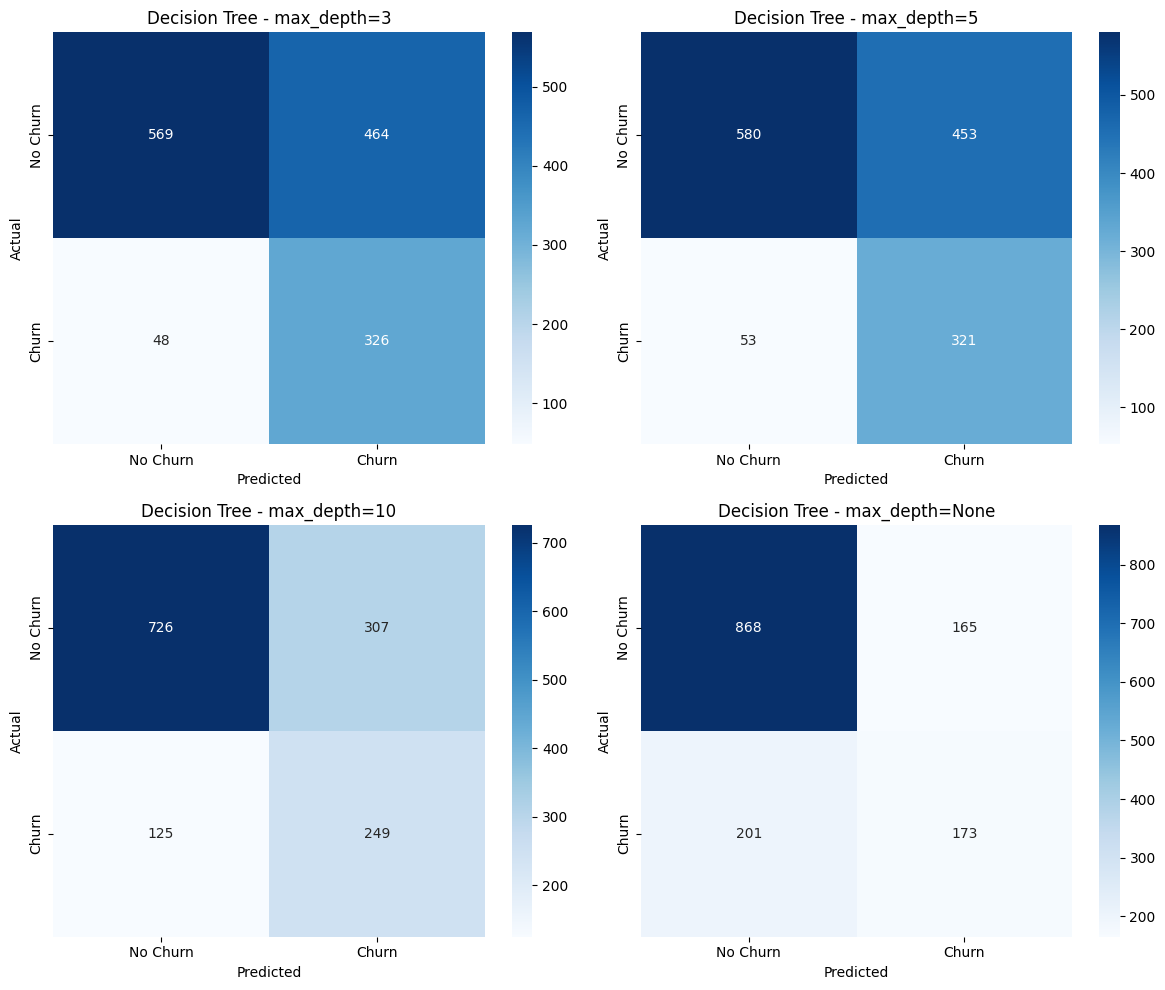

In [405]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, depth in zip(axes.flatten(), depth_values):

    cm = confusion_matrix(
        y_test_final,
        tree_predictions[depth]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(f'Decision Tree - max_depth={depth}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['No Churn', 'Churn'])
    ax.set_yticklabels(['No Churn', 'Churn'])

plt.tight_layout()
plt.show()

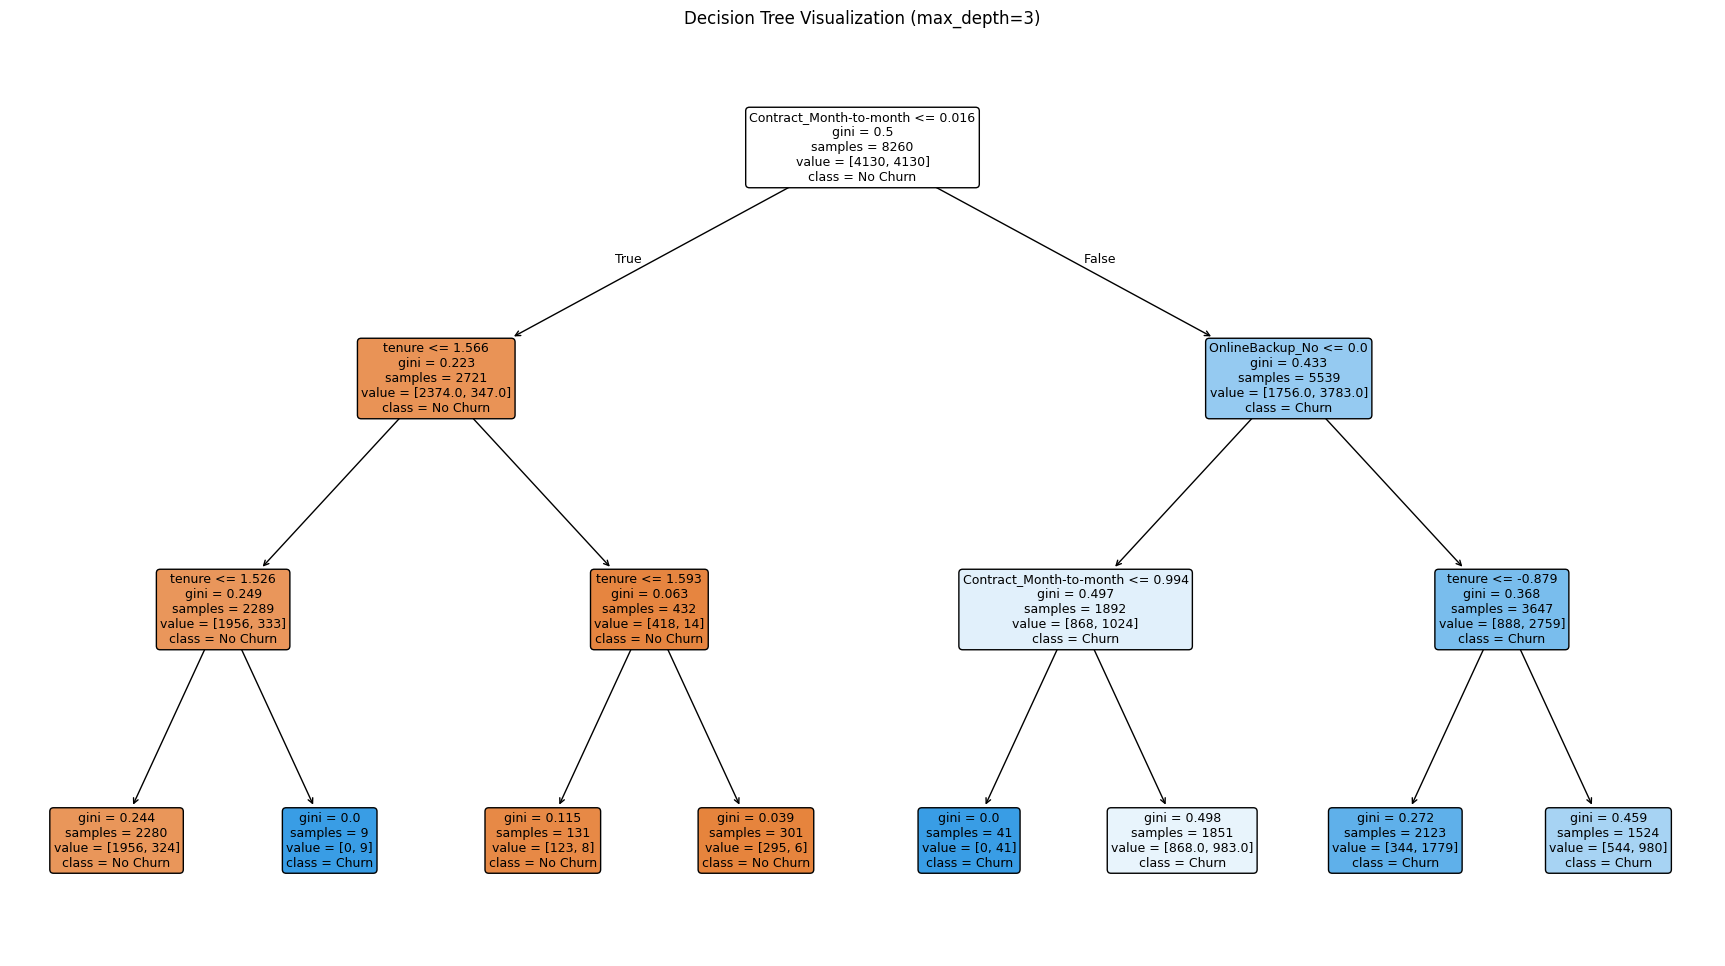

In [406]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[3],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=3)')
plt.show()

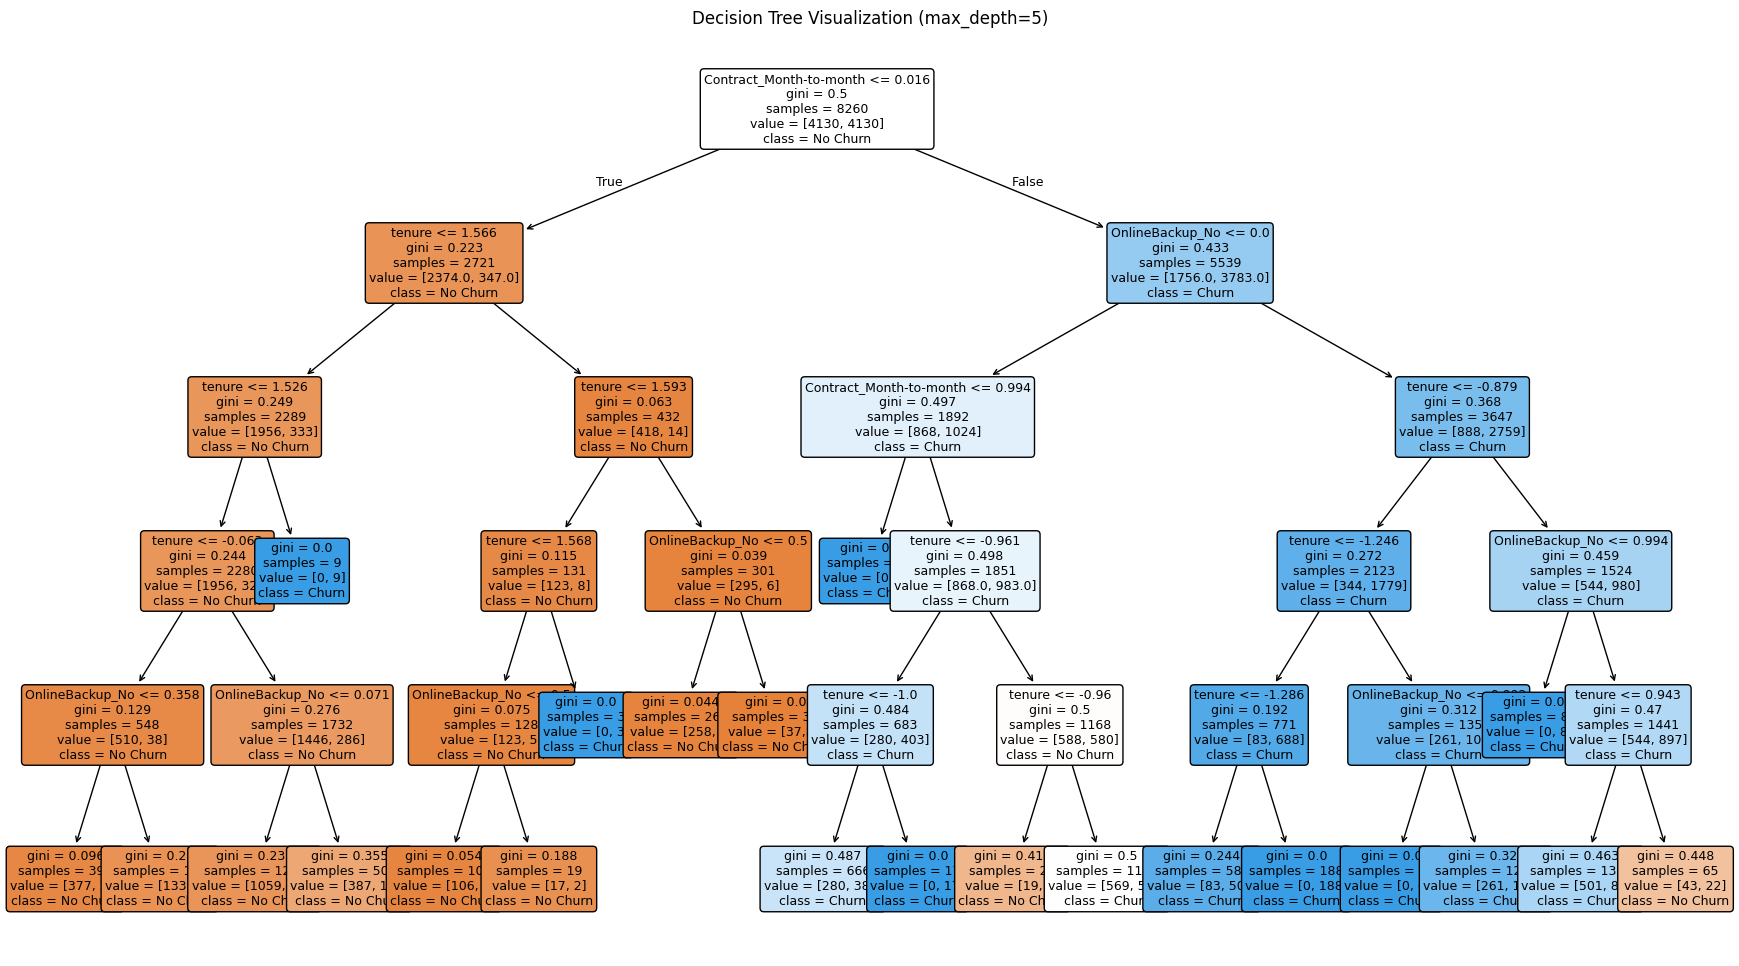

In [407]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[5],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=5)')
plt.show()

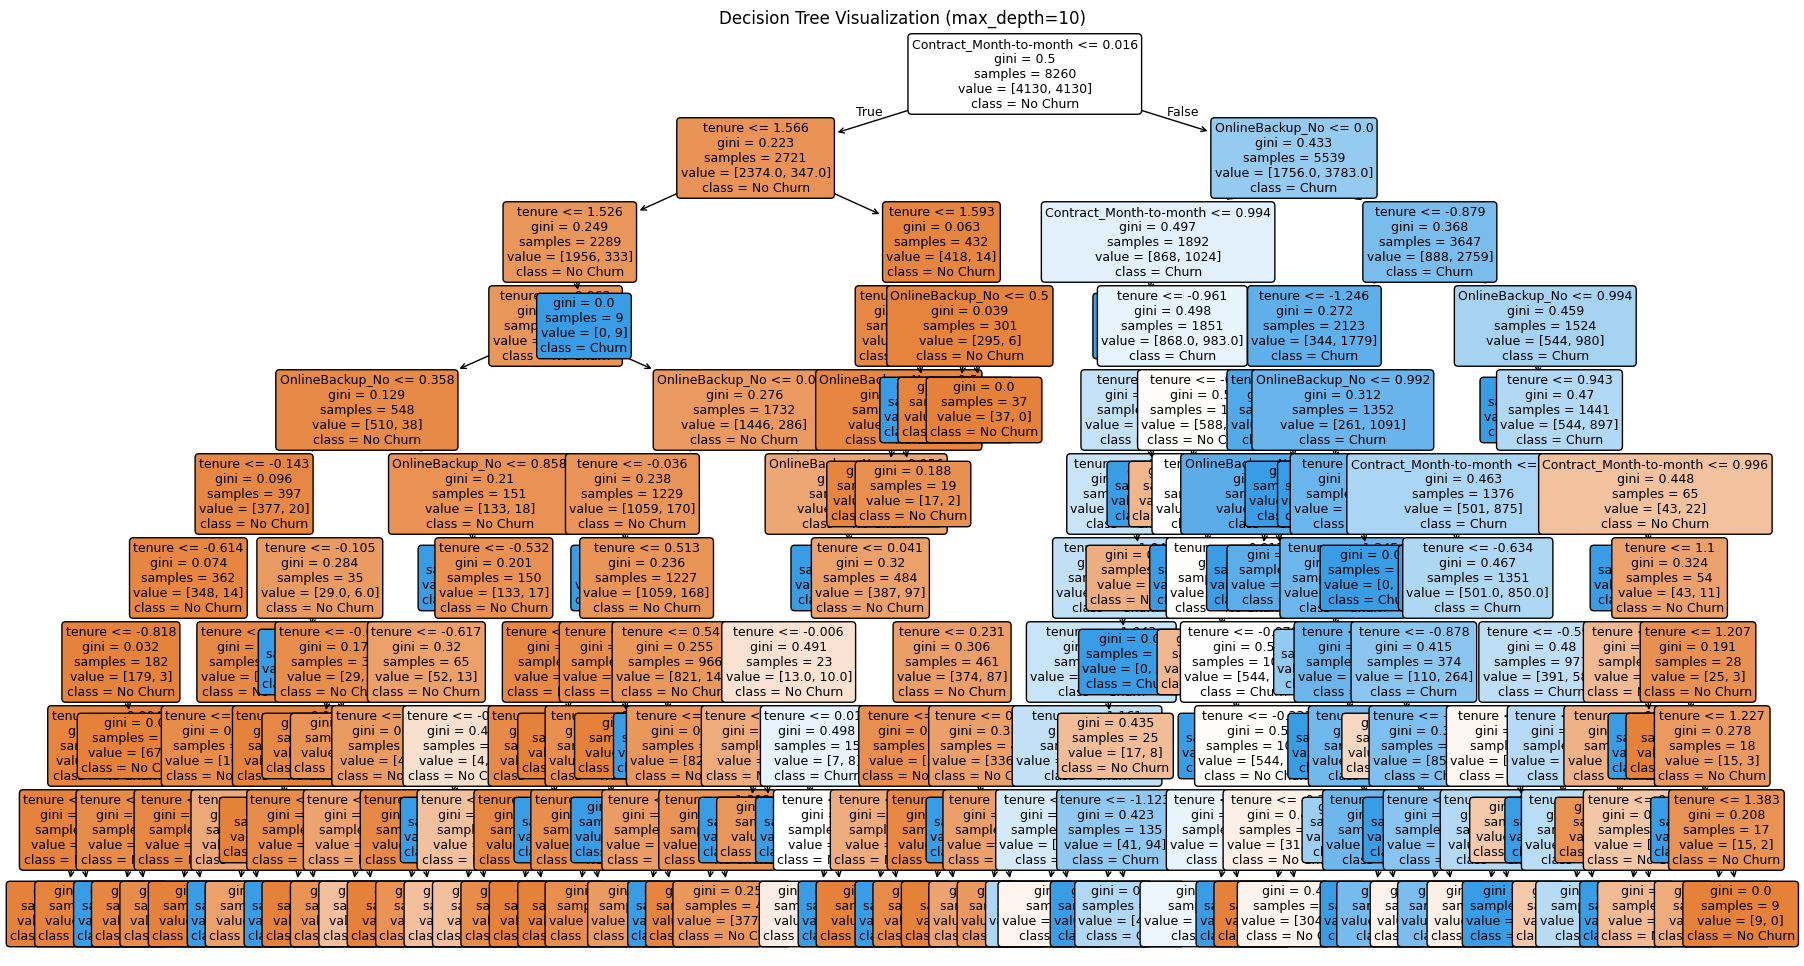

In [408]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[10],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=10)')
plt.show()

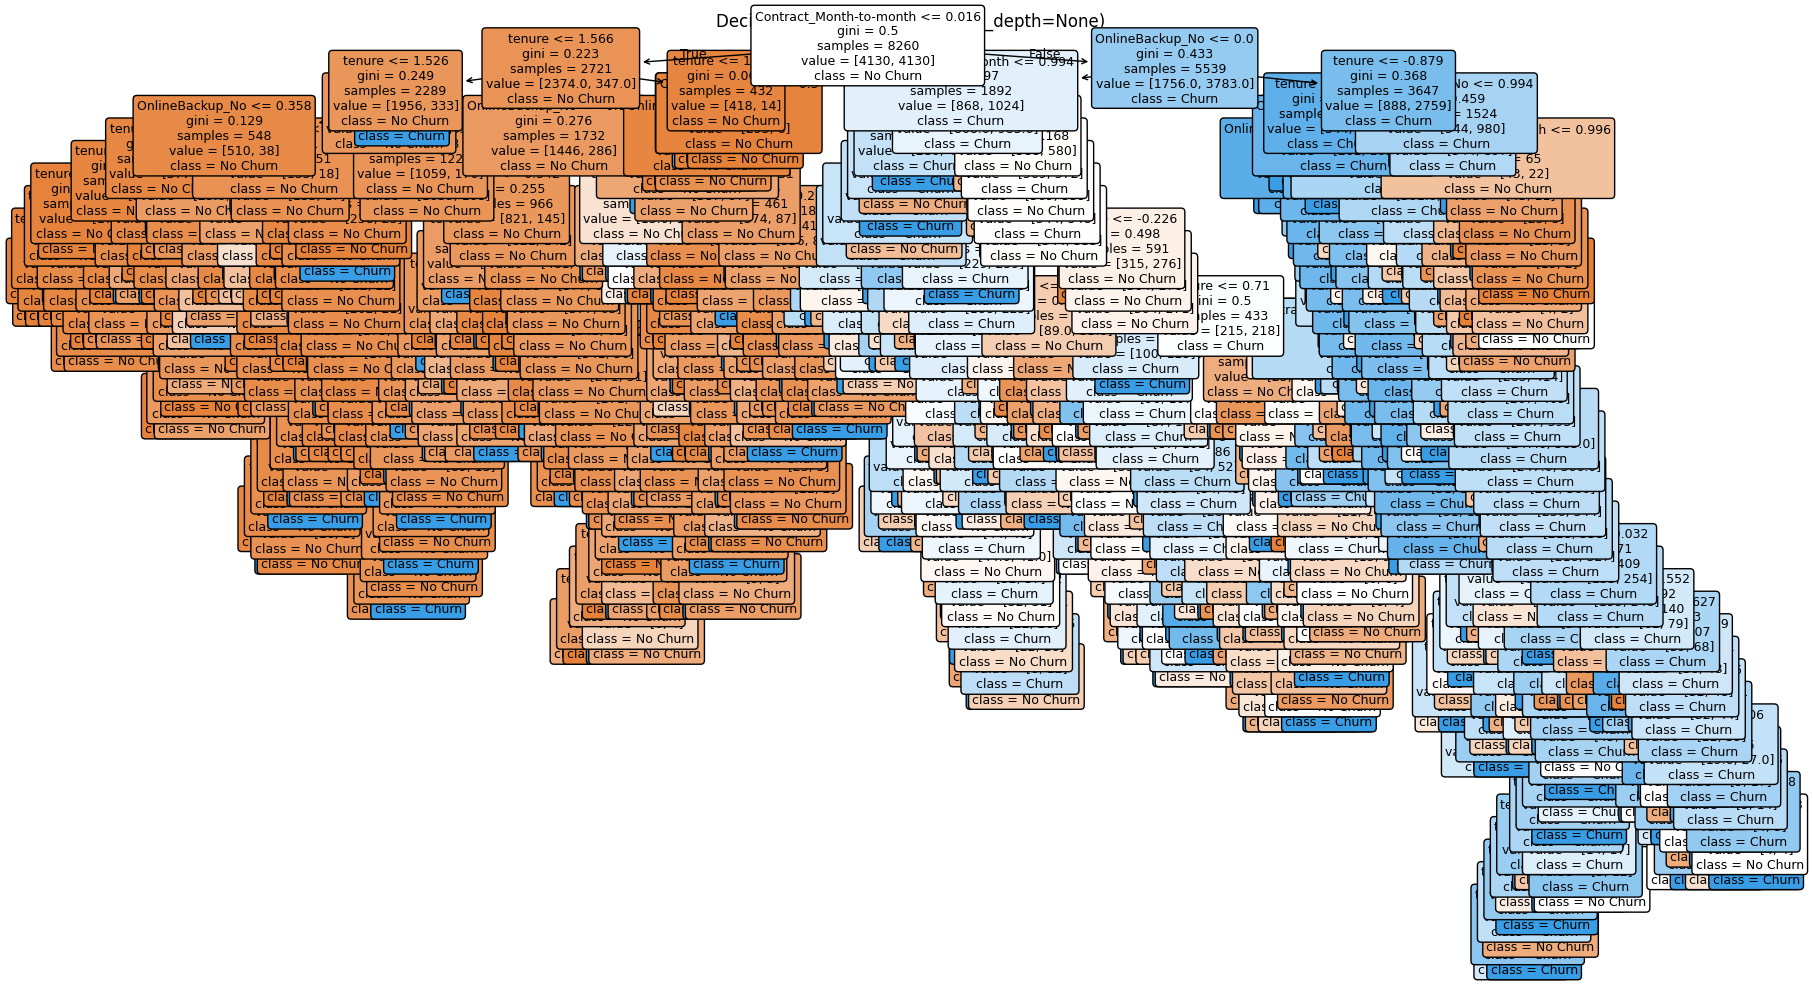

In [409]:
plt.figure(figsize=(22, 12))

plot_tree(
    tree_models[None],
    feature_names=selected_cols,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Visualization (max_depth=None)')
plt.show()

### Comparison of Classification Models

We now compare KNN, Logistic Regression and Decision Tree using the same test dataset and evaluation metrics. This helps us identify which model is more suitable for predicting customer churn.

In [410]:
comparison_df = pd.DataFrame({

    'Model': [
        'KNN',
        'Logistic Regression',
        'Decision Tree (max_depth=3)',
        'Decision Tree (max_depth=5)',
        'Decision Tree (max_depth=10)',
        'Decision Tree (max_depth=None)'
    ],

    'Accuracy': [
        accuracy_score(y_test_final, knn_pred),
        accuracy_score(y_test_final, log_reg_pred),
        *[accuracy_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'Precision': [
        precision_score(y_test_final, knn_pred),
        precision_score(y_test_final, log_reg_pred),
        *[precision_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'Recall': [
        recall_score(y_test_final, knn_pred),
        recall_score(y_test_final, log_reg_pred),
        *[recall_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ],

    'F1 Score': [
        f1_score(y_test_final, knn_pred),
        f1_score(y_test_final, log_reg_pred),
        *[f1_score(y_test_final, tree_predictions[d]) for d in depth_values]
    ]

})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7313,0.4942,0.4519,0.4721
1,Logistic Regression,0.6688,0.4359,0.8369,0.5733
2,Decision Tree (max_depth=3),0.6361,0.4127,0.8717,0.5601
3,Decision Tree (max_depth=5),0.6404,0.4147,0.8583,0.5592
4,Decision Tree (max_depth=10),0.6930,0.4478,0.6658,0.5355
5,Decision Tree (max_depth=None),0.7399,0.5118,0.4626,0.4860


### Model Comparison

We compared KNN, Logistic Regression, and Decision Tree models with different maximum depths using the same test dataset.

- **KNN** achieved an accuracy of 73.13%, but its recall was 45.19%, meaning it failed to identify many actual churn customers.
- **Logistic Regression** achieved the highest F1-score of 57.33%, providing the best balance between precision and recall among the tested models.
- **Decision Tree (max_depth=3)** achieved the highest recall of 87.17%, meaning it identified the largest proportion of actual churn customers. However, its precision was relatively low.
- **Decision Tree (max_depth=None)** achieved the highest accuracy of 73.99% and precision of 51.18%, but its recall was only 46.26%.

**Conclusion:** Logistic Regression is a reasonable balanced choice based on its highest F1-score. However, if identifying as many potential churners as possible is the main business objective, Decision Tree with `max_depth=3` is a better choice because it has the highest recall.

### Effect of Maximum Depth on Decision Tree

Changing the maximum depth affects the complexity of a Decision Tree.

- At `max_depth=3`, the model achieved the highest recall (87.17%) but relatively low accuracy (63.61%).
- At `max_depth=5`, accuracy improved slightly to 64.04%, while recall decreased to 85.83%.
- At `max_depth=10`, accuracy increased to 69.30%, but recall decreased to 66.58%.
- With `max_depth=None`, the model achieved the highest accuracy (73.99%), but recall dropped to 46.26%.

Increasing the depth allows the tree to learn more complex patterns. However, deeper trees can become more complex and may overfit the training data.

**Does increasing depth always improve performance?**

No. Increasing depth does not guarantee better performance on unseen data. In our experiments, accuracy increased with depth, but recall and F1-score did not. Therefore, the best depth depends on the evaluation metric and the business objective.